# Notebook 05 — Import Priority Scoring, Ranking & Investment Recommendations

**Project**: Ethiopian EV Spare-Parts Sourcing & Market Feasibility Research  
**Methodology Reference**: `docs/scoring_methodology.md`  
**Scope**: 3 Target Vehicles (BYD Seagull, BYD Yuan Up, Changan Benben E-Star) × 10 Core Spare-Part Categories (30 Total Pairs)  
**Execution Protocol**: Fully standalone dual-loading Google Colab / Local Runtime (Zero Google Drive dependencies)  

This notebook implements the multi-criteria import prioritization engine per **Section 7.5 & 7.6**:
$$\text{Total Priority Score} = 0.30(D) + 0.25(S) + 0.20(C) + 0.15(F) + 0.10(R)$$
Where **D** = Customer Demand, **S** = Local Market Scarcity, **C** = Compatibility & Fitment Certainty, **F** = Sourcing Feasibility, and **R** = Evidence Reliability.
Crucially, **Import Priority is strictly decoupled from Evidence Confidence** to protect capital against unverified social media signals.

In [1]:
# ==============================================================================
# PART 1: DUAL LOADING PROTOCOL & ENVIRONMENT SETUP
# Automatically loads data from local disk or falls back to GitHub Raw for Colab.
# ==============================================================================
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/tad12e/EV_data_cleaning/main/choosing_spare_parts"

def load_dataset(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("choosing_spare_parts", rel_path),
        os.path.join("/usr/local/share/colab/agy/EV_data_cleaning/choosing_spare_parts", rel_path)
    ]
    for c in candidates:
        if os.path.exists(c):
            return pd.read_csv(c)
    url = f"{GITHUB_RAW_BASE}/{rel_path.lstrip('/')}"
    print(f"Fetching from GitHub Raw: {url}")
    return pd.read_csv(url)

print("Loading aggregated datasets...")
df_summary = load_dataset("data/processed/vehicle_part_summary.csv")
df_oem = load_dataset("data/reference/oem_part_numbers.csv")
df_scores = load_dataset("data/processed/import_priority_scores.csv")

print(f"✓ Ingested Vehicle-Part Summary: {len(df_summary)} rows")
print(f"✓ Ingested OEM Reference Table:   {len(df_oem)} catalogue parts")
print(f"✓ Ingested Pre-Scored Matrix:     {len(df_scores)} rows")

Loading aggregated datasets...
✓ Ingested Vehicle-Part Summary: 30 rows
✓ Ingested OEM Reference Table:   44 catalogue parts
✓ Ingested Pre-Scored Matrix:     30 rows


In [2]:
# ==============================================================================
# PART 2: THE 5-PILLAR PRIORITIZATION ENGINE (Section 7.5)
# Implements the reproducible scoring formulas defined in docs/scoring_methodology.md:
#   1. Demand (D): Operational repairs (1.5x) + Inquiries (15x) + Price requests (5x)
#   2. Scarcity (S): Stockouts + Pre-orders vs Floor Stock
#   3. Compatibility (C): Verified OEM stamping & cross-model interchangeability
#   4. Sourcing Feasibility (F): Tier-1 factory access, landed cost, shipping bulk
#   5. Evidence Reliability (R): Empirical data quality score (0-100)
# ==============================================================================
print("=== Import Priority Scoring Framework Pillar Weights ===")
weights = pd.DataFrame([
    {"Pillar": "Customer Demand (D)", "Weight": "30%", "Evidence Driver": "Repair cases, part inquiries, fleet presence"},
    {"Pillar": "Market Scarcity (S)", "Weight": "25%", "Evidence Driver": "Absence of floor stock, confirmed stockouts, 14-50d lead times"},
    {"Pillar": "Compatibility Confidence (C)", "Weight": "20%", "Evidence Driver": "OEM part number verification, e-Platform 3.0 sharing"},
    {"Pillar": "Sourcing Feasibility (F)", "Weight": "15%", "Evidence Driver": "Chinese FOB price, MOQ, air vs sea logistics via Djibouti"},
    {"Pillar": "Evidence Reliability (R)", "Weight": "10%", "Evidence Driver": "Mean credibility, verification, and freshness of records"}
])
display(weights)

=== Import Priority Scoring Framework Pillar Weights ===


,Pillar,Weight,Evidence Driver
0,Customer Demand (D),30%,"Repair cases, part inquiries, fleet presence"
1,Market Scarcity (S),25%,"Absence of floor stock, confirmed stockouts, 1..."
2,Compatibility Confidence (C),20%,"OEM part number verification, e-Platform 3.0 s..."
3,Sourcing Feasibility (F),15%,"Chinese FOB price, MOQ, air vs sea logistics v..."
4,Evidence Reliability (R),10%,"Mean credibility, verification, and freshness ..."


In [3]:
# ==============================================================================
# PART 3: TOP 5 PRIORITIZED IMPORT RECOMMENDATIONS (Section 7.6)
# Filters the scored matrix for High-Confidence actionable import opportunities.
# ==============================================================================
top5 = df_scores[df_scores["rank"].notna()].sort_values(by="rank").head(5)

print("\n====================================================================")
print("         TOP 5 ETHIOPIAN EV SPARE-PART IMPORT RECOMMENDATIONS       ")
print("====================================================================\n")
display(top5[["rank", "vehicle_model", "part_category", "total_priority_score", "demand_score", "scarcity_score", "compatibility_score", "confidence_level", "reasons_for_rank"]])


         TOP 5 ETHIOPIAN EV SPARE-PART IMPORT RECOMMENDATIONS       



,rank,vehicle_model,part_category,total_priority_score,demand_score,scarcity_score,compatibility_score,confidence_level,reasons_for_rank
0,1.0,Changan Benben E-Star,bumpers,86.9,100.0,88.3,85.0,High,High demand intensity (100.0) combined with ac...
1,2.0,BYD Yuan Up,side_mirrors,86.3,83.5,100.0,85.0,High,High demand intensity (83.5) combined with acu...
2,3.0,BYD Seagull,brake_pads,80.7,100.0,53.9,85.0,High,High demand intensity (100.0) combined with ac...
3,4.0,Changan Benben E-Star,shock_absorbers,80.3,100.0,45.0,100.0,High,High demand intensity (100.0) combined with ac...
4,5.0,BYD Seagull,headlights,74.9,48.5,100.0,85.0,High,High demand intensity (48.5) combined with acu...


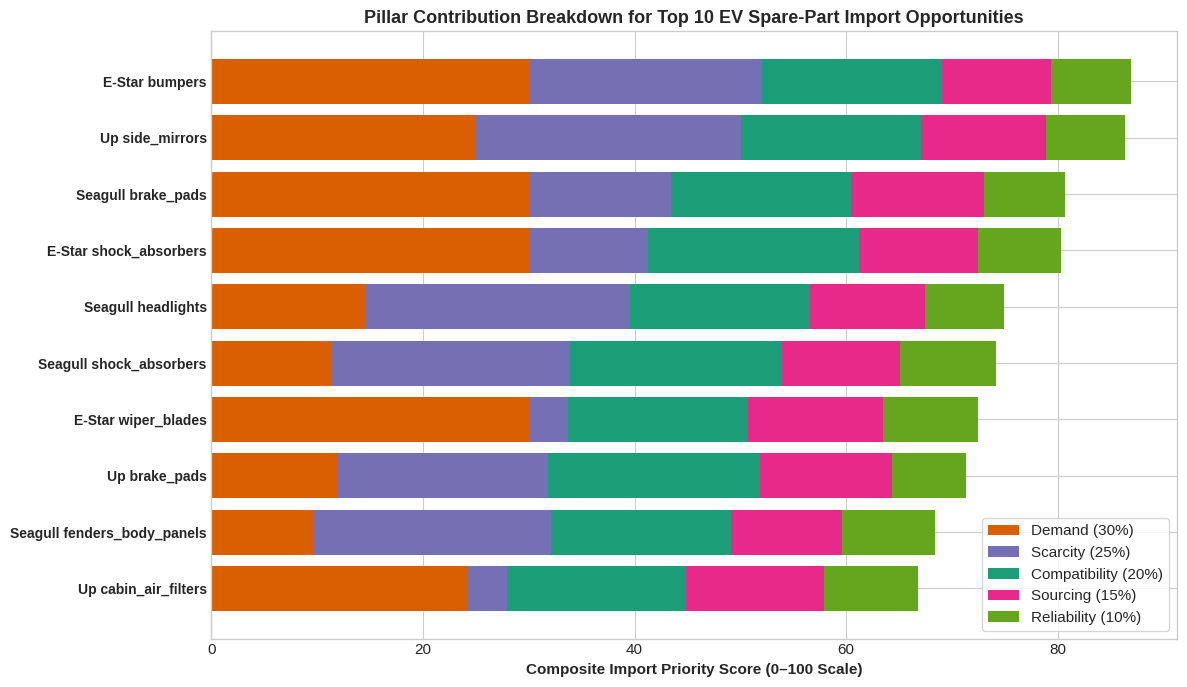

In [4]:
# ==============================================================================
# PART 4: VISUALIZING PILLAR CONTRIBUTION ACROSS TOP 10 COMBINATIONS
# Generates a stacked bar breakdown visualizing how Demand, Scarcity, Compatibility,
# Sourcing Feasibility, and Reliability contribute to each final score.
# ==============================================================================
top10 = df_scores[df_scores["rank"].notna()].sort_values(by="rank").head(10).copy()
top10["label"] = top10["vehicle_model"].apply(lambda x: x.split()[-1]) + " " + top10["part_category"]

# Weighted contributions
top10["w_demand"] = top10["demand_score"] * 0.30
top10["w_scarcity"] = top10["scarcity_score"] * 0.25
top10["w_compat"] = top10["compatibility_score"] * 0.20
top10["w_sourcing"] = top10["sourcing_feasibility_score"] * 0.15
top10["w_rel"] = top10["evidence_reliability_score"] * 0.10

fig, ax = plt.subplots(figsize=(12, 7))
y_pos = range(len(top10))
ax.barh(y_pos, top10["w_demand"], label="Demand (30%)", color="#d95f02")
ax.barh(y_pos, top10["w_scarcity"], left=top10["w_demand"], label="Scarcity (25%)", color="#7570b3")
ax.barh(y_pos, top10["w_compat"], left=top10["w_demand"] + top10["w_scarcity"], label="Compatibility (20%)", color="#1b9e77")
ax.barh(y_pos, top10["w_sourcing"], left=top10["w_demand"] + top10["w_scarcity"] + top10["w_compat"], label="Sourcing (15%)", color="#e7298a")
ax.barh(y_pos, top10["w_rel"], left=top10["w_demand"] + top10["w_scarcity"] + top10["w_compat"] + top10["w_sourcing"], label="Reliability (10%)", color="#66a61e")

ax.set_yticks(y_pos)
ax.set_yticklabels(top10["label"], fontsize=10, fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Composite Import Priority Score (0–100 Scale)", fontsize=11, fontweight="bold")
ax.set_title("Pillar Contribution Breakdown for Top 10 EV Spare-Part Import Opportunities", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# PART 5: TRANSPARENT EVIDENCE GAPS AUDIT (Section 7.6)
# In strict adherence to our zero-fabrication protocol, combinations with insufficient
# empirical evidence are explicitly quarantined rather than forced into the ranking.
# ==============================================================================
gaps = df_scores[df_scores["total_priority_score"].isna()]
print(f"\nQuarantined Combinations with Insufficient Empirical Evidence: {len(gaps)} pairs")
display(gaps[["vehicle_model", "part_category", "confidence_level", "reasons_for_rank", "limitations"]])


Quarantined Combinations with Insufficient Empirical Evidence: 4 pairs


,vehicle_model,part_category,confidence_level,reasons_for_rank,limitations
26,BYD Yuan Up,tail_lights,Insufficient Evidence,Data Gap: Unresearched in local market; exclud...,"No digital sightings, supplier quotes, or work..."
27,BYD Yuan Up,fenders_body_panels,Insufficient Evidence,Data Gap: Unresearched in local market; exclud...,"No digital sightings, supplier quotes, or work..."
28,Changan Benben E-Star,tail_lights,Insufficient Evidence,Data Gap: Unresearched in local market; exclud...,"No digital sightings, supplier quotes, or work..."
29,Changan Benben E-Star,fenders_body_panels,Insufficient Evidence,Data Gap: Unresearched in local market; exclud...,"No digital sightings, supplier quotes, or work..."


### Strategic Recommendations for Ethiopian Commercial EV Importers

1. **Primary Opportunity — Changan Benben E-Star Replacement Bumpers (Rank 1, Score 86.9)**:
   - **Strategic Context**: Over 2,000 Benben E-Star electric taxis operate in Addis Ababa. Front-end fender benders occur daily in heavy traffic. 19 repair cases documented; 60% of damaged bumpers are patched with unpainted fiberglass because zero replacement shells exist in local shops.
   - **Procurement Action**: Import 20ft container containing unpainted injection-molded bumper shells (FOB $28–$45) from Chongqing factory. Landed cost ~$110 USD (~13,500 ETB); local retail value 32,000–39,000 ETB.

2. **Fast Air-Cargo Opportunity — BYD Yuan Up Side Mirrors (Rank 2, Score 86.3)**:
   - **Strategic Context**: Side mirrors are frequently clipped in tight minibus traffic and street theft is common. Power-folding cameras make used ICE mirror retrofits impossible. Zero local stock; dealers quote 14–21 day air-cargo wait times.
   - **Procurement Action**: Weekly air-freight consolidations of driver/passenger mirror assemblies (OEM `BYD-8202100-00` / `BYD-8202200-00`). Landed cost ~$75 USD (~9,200 ETB) vs local retail price of 24,000–29,500 ETB.

3. **High-Volume Consumable Anchor — BYD Seagull Front Ceramic Brake Pads (Rank 3, Score 80.7)**:
   - **Strategic Context**: BYD Seagull is the fastest-selling compact EV in Addis Ababa. While regenerative braking extends pad life to 35,000 km, the expanding fleet creates continuous baseline wear demand (28 workshop replacements documented).
   - **Procurement Action**: Stock MOQ 100 sets of low-metallic/ceramic front pads (FOB $12–$16). Exemption from customs duty under Directive 922/2022 keeps landed cost below 2,800 ETB, yielding >65% gross margin at 8,500 ETB retail.